# Tracking Error & Risk Attribution vs Benchmark

A treasury portfolio is usually measured against a benchmark set by the board, and its managers may deviate from it only within a risk budget. The risk function then has to say how much active risk is being run, where it comes from, and whether the forecast held up. This notebook answers all three for a realistic portfolio.

**What it does.** It measures how far an MDB-style treasury portfolio can deviate from its benchmark (1–7 year U.S. Treasuries), explains where that tracking error comes from, and checks the forecast against three years of realised returns.

**Data.** Live bond-level holdings of six iShares ETFs (GOVT, AGZ, MUB and IGIB for the portfolio; SHY and IEI for the benchmark), the Treasury curve (U.S. Treasury and FRED), ICE BofA OAS by rating (FRED), and three years of daily ETF total returns (Yahoo Finance).

**Methods.** A holdings-based factor risk model (ten key rates plus four credit-spread factors), ex-ante tracking error with Euler risk decomposition by factor and by sleeve, and a PCA view of the active curve exposure.

The forecast is checked with ex-post tracking error, the information ratio and returns-based attribution, and the reporting is done in SQL (DuckDB).

**Key output.** Ex-ante against ex-post tracking error, the risk budget by factor and sleeve, the active key-rate profile, active-return contributions by sleeve, and a tracking-error dashboard.

## 1. Managing against a benchmark

An MDB's liquidity portfolio is usually managed against a **benchmark** set by the board: here, short and intermediate US Treasuries. The portfolio managers may deviate from it, by buying agencies, munis, bank and corporate bonds or by positioning on the curve, within a **tracking-error budget**: the annualised volatility of the portfolio's return minus the benchmark's.

The risk function must answer three questions:

1. **How much active risk are we running today?** The *ex-ante* tracking error, from holdings and a factor model.
2. **Where does it come from?** Duration, curve shape and the credit-spread bets of each sleeve, through an additive decomposition that a committee can act on.
3. **Was the model right?** The *ex-post* tracking error from realised returns, and how the active return actually decomposed.

## 2. The risk model

Each bond's value depends on ten key Treasury rates and, for credit sleeves, on its sector's spread. With $\mathbf{x}$ the vector of **active** exposures (portfolio minus benchmark, both scaled to the same market value) in dollars per basis point, and $\Delta\mathbf{f}$ the daily factor moves in bp:

$$
\text{active P\&L} = -\mathbf{x}^\top \Delta\mathbf{f}, \qquad
\text{TE}_{\text{ex-ante}} = \frac{\sqrt{252\;\mathbf{x}^\top \boldsymbol{\Sigma}\,\mathbf{x}}}{\text{MV}} .
$$

**Euler decomposition.** TE is homogeneous of degree one in $\mathbf{x}$, so it splits exactly into contributions that add up to the total:

$$
\text{TE} = \sum_k \underbrace{x_k\,\frac{(\boldsymbol{\Sigma}\mathbf{x})_k}{\mathbf{x}^\top\boldsymbol{\Sigma}\mathbf{x}}\;\text{TE}}_{\text{contribution of factor }k}.
$$

The same formula with the exposures of each sleeve gives each sleeve's contribution. The **ex-post** tracking error is simply the annualised standard deviation of realised daily active returns.

## 3. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import QuantLib as ql
import statsmodels.api as sm
import yfinance as yf
from scipy.optimize import brentq
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

# --- Portfolio (MDB-style liquidity portfolio) and benchmark
PORTFOLIO_SIZE_USD = 1_000_000_000
SLEEVE_TARGETS = {
    "US Treasuries": 0.40,
    "Agencies": 0.20,
    "Sub-sovereigns": 0.10,
    "Banks": 0.15,
    "Corporates": 0.15,
}
BONDS_PER_SLEEVE = 30
MATURITY_RANGE_Y = (1.0, 30.0)
KEY_TENORS = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30])
# 1–3Y and 3–7Y Treasuries, 50/50
BENCHMARK_FUNDS = {"SHY": 0.5, "IEI": 0.5}

# --- Risk model
# three years of daily factor moves
RISK_WINDOW_DAYS = 756
SPREAD_FACTOR = {
    "Agencies": "BAMLC0A1CAAA",
    "Sub-sovereigns": "BAMLC0A2CAA",
    "Banks": "BAMLC0A3CA",
    "Corporates": "BAMLC0A4CBBB",
}
# hypothetical board-approved tracking-error budget
TE_BUDGET_BP = 75

# --- Ex-post: ETF proxies for each sleeve and for the benchmark
SLEEVE_ETF = {
    "US Treasuries": "GOVT",
    "Agencies": "AGZ",
    "Sub-sovereigns": "MUB",
    "Banks": "IGIB",
    "Corporates": "IGIB",
}

print(
    f"QuantLib {ql.__version__} · DuckDB {duckdb.__version__} · yfinance"
    f" {yf.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · DuckDB 1.5.6 · yfinance 1.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 4. Data

### 4.1 Holdings of the portfolio and of the benchmark

| Sleeve | ETF | Product id |
|---|---|---|
| US Treasuries | GOVT | 239468 |
| Agencies | AGZ | 239457 |
| Sub-sovereigns | MUB | 239766 |
| Banks / Corporates | IGIB (split by sector) | 239463 |
| **Benchmark** 1–3Y Treasuries | SHY | 239452 |
| **Benchmark** 3–7Y Treasuries | IEI | 239455 |

The benchmark uses **every** Treasury in SHY and IEI at its fund weight, a faithful replica of a 1–7 year Treasury index.

In [3]:
ISHARES_FUNDS = {
    "GOVT": "239468",
    "AGZ": "239457",
    "MUB": "239766",
    "IGIB": "239463",
    "SHY": "239452",
    "IEI": "239455",
}
SLEEVE_BY_FUND = {
    "GOVT": "US Treasuries",
    "AGZ": "Agencies",
    "MUB": "Sub-sovereigns",
    "SHY": "Benchmark",
    "IEI": "Benchmark",
}


def fetch_holdings(ticker: str) -> pd.DataFrame:
    """
    Download one iShares fund's holdings file and return the holdings table as
    text columns.
    """
    url = f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv"
    lines = requests.get(
        url, headers=BROWSER_HEADERS, timeout=30
    ).text.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    header = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    table = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    table["fund"], table["as_of"] = ticker, as_of
    return table


raw_holdings = pd.concat(
    [
        cached(f"ishares_{t}", lambda t=t: fetch_holdings(t))
        for t in ISHARES_FUNDS
    ],
    ignore_index=True,
)


def to_number(s):
    """'1,234.50' -> 1234.5 ; '-' or '' -> NaN."""
    return pd.to_numeric(
        s.astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    )


col = lambda name, default="": (
    raw_holdings[name]
    if name in raw_holdings
    else pd.Series(default, index=raw_holdings.index)
)
bonds = pd.DataFrame({
    "fund": raw_holdings["fund"],
    "name": raw_holdings["Name"],
    "sector": col("Sector").fillna(""),
    "asset_class": col("Asset Class").fillna(""),
    "currency": col("Currency", "USD").fillna(""),
    "isin": col("ISIN"),
    "weight_pct": to_number(raw_holdings["Weight (%)"]),
    "clean_price": to_number(col("Price", np.nan)),
    "coupon_pct": to_number(raw_holdings["Coupon (%)"]),
    "ishares_duration": to_number(col("Duration", np.nan)),
    "ishares_ytm_pct": to_number(col("YTM (%)", np.nan)),
    "maturity": pd.to_datetime(
        raw_holdings["Maturity"], format="%b %d, %Y", errors="coerce"
    ).fillna(
        pd.to_datetime(
            raw_holdings["Maturity"], format="mixed", errors="coerce"
        )
    ),
    "as_of": raw_holdings["as_of"],
})
# Sleeve = the fund it came from; the corporate fund is split into banks and
# other corporates by sector
bonds["sleeve"] = [
    SLEEVE_BY_FUND.get(f)
    or ("Banks" if re.search("bank", s, re.I) else "Corporates")
    for f, s in zip(bonds["fund"], bonds["sector"])
]


def clean_price_from_ytm(coupon_pct, ytm_pct, maturity, settle):
    """
    Clean price per 100 from a semi-annual yield, used when a holdings file has
    no Price column.
    """
    if (
        any(pd.isna(v) for v in (coupon_pct, ytm_pct, maturity, settle))
        or maturity <= settle
    ):
        return np.nan
    c, y = coupon_pct / 2, ytm_pct / 200
    # coupon dates, walking back from maturity
    dates = [maturity]
    while dates[-1] > settle:
        dates.append(dates[-1] - pd.DateOffset(months=6))
    prev, cfs = dates[-1], sorted(dates[:-1])
    # fraction of the first period still to run
    frac = (cfs[0] - settle).days / (cfs[0] - prev).days
    dirty = sum(c / (1 + y) ** (frac + k) for k in range(len(cfs))) + 100 / (
        1 + y
    ) ** (frac + len(cfs) - 1)
    # remove accrued interest
    return dirty - c * (1 - frac)


missing_price = bonds["clean_price"].isna() & bonds["ishares_ytm_pct"].notna()
settle = pd.to_datetime(bonds["as_of"], format="%b %d, %Y", errors="coerce")
bonds.loc[missing_price, "clean_price"] = [
    clean_price_from_ytm(c, y, m, s)
    for c, y, m, s in zip(
        bonds.loc[missing_price, "coupon_pct"],
        bonds.loc[missing_price, "ishares_ytm_pct"],
        bonds.loc[missing_price, "maturity"],
        settle[missing_price],
    )
]
if missing_price.any():
    print(
        "Clean price rebuilt from iShares YTM for"
        f" {missing_price.sum()} holdings"
        f" ({', '.join(bonds.loc[missing_price, 'fund'].unique())}: file has"
        " no Price column)"
    )
print(
    f"{len(bonds):,} holdings parsed · "
    + ", ".join(f"{f} {n:,}" for f, n in bonds["fund"].value_counts().items())
)

Clean price rebuilt from iShares YTM for 119 holdings (AGZ: file has no Price column)
11,183 holdings parsed · MUB 7,604, IGIB 3,053, GOVT 231, AGZ 119, SHY 92, IEI 84


### 4.2 Treasury curve and 10 years of daily moves

In [4]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    """
    Daily Treasury par yield curves for the current year (falls back to last
    year in early January).
    """
    get = lambda year: pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    raw = get(dt.date.today().year)
    if len(raw) < 20:  # early January: add last year's file
        raw = pd.concat(
            [raw, get(dt.date.today().year - 1)], ignore_index=True
        )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

FRED_KEY_SERIES = {
    "DGS3MO": 0.25,
    "DGS6MO": 0.5,
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_history():
    frames = []
    for sid, tenor in FRED_KEY_SERIES.items():
        s = fred.get_series(
            sid, observation_start=EVAL_DATE - pd.Timedelta(days=3653)
        ).dropna()
        frames.append(
            pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        )
    return pd.concat(frames, ignore_index=True)


history = (
    cached("fred_treasury_key_rates", fetch_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()[list(KEY_TENORS)]
    .dropna()
)
daily_changes_bp = history.diff().dropna() * 100
print(
    f"Evaluation date {EVAL_DATE:%Y-%m-%d} · {len(daily_changes_bp):,} daily"
    f" curve moves ({daily_changes_bp.index.min():%Y} →"
    f" {daily_changes_bp.index.max():%Y})"
)

Evaluation date 2026-10-16 · 2,498 daily curve moves (2016 → 2026)


### 4.3 Credit-spread factors and ETF total returns

- **ICE BofA OAS** for the AAA, AA, A and BBB buckets (FRED), one spread factor per credit sleeve.
- **Daily total returns** (dividends reinvested) of the six ETFs over three years (Yahoo Finance), used for the ex-post analysis.

In [5]:
def fetch_oas():
    frames = [
        pd.DataFrame({"date": s.index, "series": sid, "value": s.values})
        for sid in SPREAD_FACTOR.values()
        for s in [fred.get_series(sid).dropna()]
    ]
    return pd.concat(frames, ignore_index=True)


# bp
oas = (
    cached("fred_ice_oas", fetch_oas)
    .pivot(index="date", columns="series", values="value")
    .sort_index()
    * 100
)

ETFS = sorted(set(SLEEVE_ETF.values()) | set(BENCHMARK_FUNDS))


def fetch_etf_prices():
    px = yf.download(
        ETFS,
        start=EVAL_DATE - pd.Timedelta(days=3 * 365 + 30),
        end=EVAL_DATE + pd.Timedelta(days=1),
        auto_adjust=True,
        progress=False,
    )["Close"]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name, px.columns.name = "date", None
    return px.reset_index()


prices = (
    cached("yahoo_etf_total_return", fetch_etf_prices)
    .set_index("date")
    .sort_index()
)

# --- Data cleaning: Yahoo occasionally prints a bad close that reverses the
# next day (a one-day spike).
# Flag days whose return is extreme for that fund AND is undone by the next
# day's return, then interpolate.
raw_ret = prices.pct_change()
# robust daily σ
scale = raw_ret.abs().rolling(60, min_periods=20).median().shift() / 0.6745
spike = (raw_ret.abs() > 8 * scale) & (
    (raw_ret + raw_ret.shift(-1)).abs() < 0.25 * raw_ret.abs()
)
for etf in prices.columns[spike.any()]:
    print(
        f"Data fix · {etf}: bad print on"
        f" {', '.join(f'{d:%Y-%m-%d}' for d in spike.index[spike[etf]])} replaced"
        " by interpolation"
    )
prices = prices.mask(spike).interpolate(limit_area="inside")
returns = prices.pct_change().dropna()
print(
    f"OAS factors {oas.index.min():%Y-%m-%d} → {oas.index.max():%Y-%m-%d} ·"
    f" ETF returns {returns.index.min():%Y-%m-%d} →"
    f" {returns.index.max():%Y-%m-%d} ({len(returns):,} days)"
)

Data fix · GOVT: bad print on 2024-12-31 replaced by interpolation
OAS factors 2023-10-20 → 2026-10-16 · ETF returns 2023-09-19 → 2026-10-16 (773 days)


## 5. Portfolio, benchmark and their exposures

The portfolio is an MDB-style liquidity portfolio of real bonds. The benchmark's Treasuries are scaled to the same USD 1 bn. Every bond, in both books, is priced on the Treasury zero curve plus its own Z-spread, and then bumped at each key rate (KR01) and, for credit sleeves, in spread (CS01).

In [6]:
today = EVAL_DATE.normalize()
bonds["years_to_maturity"] = (bonds["maturity"] - today).dt.days / 365.25
eligible = bonds[
    bonds["currency"].eq("USD")
    & bonds["clean_price"].gt(0)
    & bonds["coupon_pct"].notna()
    & bonds["years_to_maturity"].between(*MATURITY_RANGE_Y)
    & ~bonds["asset_class"].str.contains(
        "Cash|Money Market|Futures", case=False
    )
    & bonds["sleeve"].isin(SLEEVE_TARGETS)
].copy()

# The largest holdings of each sleeve, re-weighted to the sleeve's target share
# of the portfolio
portfolio = (
    eligible.sort_values("weight_pct", ascending=False)
    .groupby("sleeve", group_keys=False)
    .head(BONDS_PER_SLEEVE)
    .copy()
)
portfolio["market_value"] = (
    portfolio.groupby("sleeve")["weight_pct"].transform(lambda w: w / w.sum())
    * portfolio["sleeve"].map(SLEEVE_TARGETS)
    * PORTFOLIO_SIZE_USD
)
portfolio = portfolio.reset_index(drop=True)
SLEEVE_COLORS = dict(zip(SLEEVE_TARGETS, PALETTE))

portfolio.groupby("sleeve").agg(
    bonds=("name", "size"),
    market_value_mm=("market_value", lambda v: v.sum() / 1e6),
    avg_coupon_pct=("coupon_pct", "mean"),
    avg_maturity_y=("years_to_maturity", "mean"),
).reindex(SLEEVE_TARGETS)

,bonds,market_value_mm,avg_coupon_pct,avg_maturity_y
sleeve,,,,
US Treasuries,30,400.00,3.28,6.53
Agencies,30,200.00,4.43,4.10
Sub-sovereigns,30,100.00,4.93,16.47
Banks,30,150.00,5.22,8.51
Corporates,30,150.00,4.88,8.16


In [7]:
bench = bonds[
    bonds["sleeve"].eq("Benchmark")
    & bonds["currency"].eq("USD")
    & bonds["clean_price"].gt(0)
    & bonds["coupon_pct"].notna()
    & ~bonds["asset_class"].str.contains(
        "Cash|Money Market|Futures", case=False
    )
].copy()
bench["years_to_maturity"] = (bench["maturity"] - today).dt.days / 365.25
bench = bench[bench["years_to_maturity"] > 0.1]
bench["market_value"] = (
    bench.groupby("fund")["weight_pct"].transform(lambda w: w / w.sum())
    * bench["fund"].map(BENCHMARK_FUNDS)
    * PORTFOLIO_SIZE_USD
)
portfolio["book"], bench["book"] = "Portfolio", "Benchmark"
# priced together below, split afterwards
portfolio = pd.concat([portfolio, bench], ignore_index=True)
print(
    f"Benchmark: {len(bench)} Treasuries · average maturity "
    f"{np.average(bench['years_to_maturity'], weights=bench['market_value']):.2f} years"
)

Benchmark: 172 Treasuries · average maturity 3.33 years


In [8]:
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)


def build_treasury_curve(par_row):
    """
    Bootstrap a Treasury zero curve from one day's par yields (bills as zeros,
    notes/bonds at par).
    """
    helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
    for tenor, par_yield in par_row.items():
        y = par_yield / 100
        period = (
            ql.Period(int(round(tenor * 52)), ql.Weeks)
            if tenor < 1
            else ql.Period(int(round(tenor * 12)), ql.Months)
        )
        maturity = US_GOVT.advance(ql_today, period)
        freq, coupons, price = (
            (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
            if tenor <= 1
            else (ql.Semiannual, [y], 100.0)
        )
        schedule = ql.Schedule(
            ql_today,
            maturity,
            ql.Period(freq),
            US_GOVT,
            ql.Unadjusted,
            ql.Unadjusted,
            ql.DateGeneration.Backward,
            False,
        )
        helpers.append(
            ql.FixedRateBondHelper(
                ql.QuoteHandle(ql.SimpleQuote(price)),
                0,
                100.0,
                schedule,
                coupons,
                bond_dc,
            )
        )
    curve = ql.PiecewiseConvexMonotoneForward(
        ql_today, helpers, ql.Actual365Fixed()
    )
    curve.enableExtrapolation()
    return curve


ust_curve = build_treasury_curve(par_today)
GRID_T = np.linspace(1 / 365, 31, 31 * 52)
# continuous zero rates
GRID_Z = np.array(
    [ust_curve.zeroRate(float(t), ql.Continuous).rate() for t in GRID_T]
)


def zero_rate(t):
    """
    Treasury zero rate (decimal, continuous) at times t (years), by
    interpolation on the grid.
    """
    return np.interp(t, GRID_T, GRID_Z)


def cash_flows(coupon_pct, years_to_maturity):
    """
    Times (years) and amounts per 100 face of a semi-annual fixed-coupon bond.
    """
    times = np.arange(years_to_maturity, 0, -0.5)[::-1]
    amounts = np.full(len(times), coupon_pct / 2)
    amounts[-1] += 100
    return times, amounts


def price_from_curve(times, amounts, spread, shift=None, zero=None):
    """
    Dirty price per 100 face on a zero curve + constant spread (+ an optional
    bump function of t).
    """
    z = (
        (zero_rate(times) if zero is None else zero(times))
        + spread
        + (0 if shift is None else shift(times))
    )
    return float(np.sum(amounts * np.exp(-z * times)))


records = []
for i, b in portfolio.iterrows():
    times, amounts = cash_flows(b["coupon_pct"], b["years_to_maturity"])
    # linear accrual since the last coupon
    accrued = b["coupon_pct"] / 2 * (1 - times[0] / 0.5)
    dirty = b["clean_price"] + accrued
    try:
        z_spread = brentq(
            lambda s: price_from_curve(times, amounts, s) - dirty, -0.05, 0.20
        )
    # price outside any reasonable spread (bad print): dropped below
    except ValueError:
        z_spread = np.nan
    records.append({
        "times": times,
        "amounts": amounts,
        "accrued": accrued,
        "dirty_price": dirty,
        "z_spread_bp": z_spread * 1e4,
    })

portfolio = pd.concat([portfolio, pd.DataFrame(records)], axis=1)
dropped = portfolio["z_spread_bp"].isna().sum()
portfolio = portfolio.dropna(subset=["z_spread_bp"]).reset_index(drop=True)
# USD face amount held
portfolio["face"] = portfolio["market_value"] / portfolio["dirty_price"] * 100
print(
    f"Treasury zero curve: "
    + ", ".join(
        f"{tenor_label(t)} {zero_rate(t)*100:.2f}%"
        for t in (0.5, 2, 5, 10, 30)
    )
    + (
        f" · {dropped} bond(s) dropped (price inconsistent with any spread)"
        if dropped
        else ""
    )
)

Treasury zero curve: 6M 4.31%, 2Y 4.69%, 5Y 4.84%, 10Y 5.06%, 30Y 5.41%


In [9]:
def triangle(k):
    nodes = np.zeros(len(KEY_TENORS))
    nodes[k] = 1.0
    return lambda t: np.interp(t, KEY_TENORS, nodes) * 1e-4


BUMPS = [triangle(k) for k in range(len(KEY_TENORS))]
kr01 = np.zeros((len(portfolio), len(KEY_TENORS)))
cs01 = np.zeros(len(portfolio))
for i, b in portfolio.iterrows():
    t, cf, s = b["times"], b["amounts"], b["z_spread_bp"] / 1e4
    base, scale = price_from_curve(t, cf, s), b["face"] / 100
    kr01[i] = [
        (base - price_from_curve(t, cf, s, bump)) * scale for bump in BUMPS
    ]
    cs01[i] = (base - price_from_curve(t, cf, s + 1e-4)) * scale

TENOR_COLS = [f"KR01_{tenor_label(k)}" for k in KEY_TENORS]
expo = pd.concat(
    [
        portfolio[[
            "book",
            "sleeve",
            "name",
            "maturity",
            "market_value",
            "z_spread_bp",
        ]],
        pd.DataFrame(kr01, columns=TENOR_COLS),
    ],
    axis=1,
)
# no spread factor for Treasuries
expo["CS01"] = np.where(expo["sleeve"].isin(SPREAD_FACTOR), cs01, 0.0)
expo["DV01"] = kr01.sum(axis=1)

con = duckdb.connect()
con.register("expo", expo)
con.sql("""
    SELECT book, sleeve, COUNT(*) AS bonds, SUM(market_value) / 1e6 AS mv_mm,
           SUM(DV01) / SUM(market_value) * 1e4 AS duration, SUM(DV01) / 1e3 AS dv01_k, SUM(CS01) / 1e3 AS cs01_k
    FROM expo GROUP BY ALL ORDER BY book DESC, mv_mm DESC
""").df().round(2)

,book,sleeve,bonds,mv_mm,duration,dv01_k,cs01_k
0,Portfolio,US Treasuries,30,400.00,5.07,202.68,0.00
1,Portfolio,Agencies,30,200.00,3.41,68.27,68.26
2,Portfolio,Banks,30,150.00,6.74,101.14,101.13
3,Portfolio,Corporates,30,150.00,6.68,100.13,100.11
4,Portfolio,Sub-sovereigns,30,100.00,9.89,98.87,98.84
5,Benchmark,Benchmark,172,"1,000.00",3.09,309.34,0.00


### 5.1 The active positions

Active exposure = portfolio minus benchmark. Positive KR01 means the portfolio loses more than the benchmark when that rate rises. The SQL builds the vector the risk model needs: ten active KR01s and four CS01s.

In [10]:
active_sql = ", ".join(
    f"SUM(CASE WHEN book = 'Portfolio' THEN {c} ELSE -{c} END) AS {c}"
    for c in TENOR_COLS
)
active_kr = con.sql(f"SELECT {active_sql} FROM expo").df().iloc[0].values
active_cs = (
    con.sql(
        "SELECT sleeve, SUM(CS01) AS cs01 FROM expo WHERE book = 'Portfolio'"
        " AND CS01 <> 0 GROUP BY sleeve"
    )
    .df()
    .set_index("sleeve")["cs01"]
    .reindex(list(SPREAD_FACTOR))
    .values
)
FACTORS = [tenor_label(k) for k in KEY_TENORS] + [
    f"Spread {s}" for s in SPREAD_FACTOR
]
x = np.r_[active_kr, active_cs]  # $ per bp, active

dur = (
    lambda book: expo.loc[expo["book"] == book, "DV01"].sum()
    / PORTFOLIO_SIZE_USD
    * 1e4
)
print(
    f"Duration: portfolio {dur('Portfolio'):.2f} · benchmark"
    f" {dur('Benchmark'):.2f} · active"
    f" {dur('Portfolio') - dur('Benchmark'):+.2f} years"
)
pd.DataFrame({"active exposure ($k per bp)": x / 1e3}, index=FACTORS).T.round(
    1
)

Duration: portfolio 5.71 · benchmark 3.09 · active +2.62 years


,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y,Spread Agencies,Spread Sub-sovereigns,Spread Banks,Spread Corporates
active exposure ($k per bp),0.10,0.20,-8.70,-16.30,-32.30,-28.70,78.50,149.00,92.80,27.20,68.30,98.80,101.10,100.10


## 6. Ex-ante tracking error and where it comes from

The factor covariance uses the last three years of daily moves: Treasury key rates (FRED) and OAS buckets (ICE), aligned on common dates.

In [11]:
factor_moves = (
    pd.concat(
        [
            daily_changes_bp.set_axis(
                [tenor_label(k) for k in KEY_TENORS], axis=1
            ),
            oas.diff().rename(
                columns={v: f"Spread {k}" for k, v in SPREAD_FACTOR.items()}
            ),
        ],
        axis=1,
        join="inner",
    )
    .dropna()
    .iloc[-RISK_WINDOW_DAYS:][FACTORS]
)
SIGMA = factor_moves.cov().values
var_daily = x @ SIGMA @ x
TE_EXANTE_BP = np.sqrt(252 * var_daily) / PORTFOLIO_SIZE_USD * 1e4
# Euler contributions, bp, sum to TE
contrib = x * (SIGMA @ x) / var_daily * TE_EXANTE_BP

decomp = pd.DataFrame(
    {
        "active exposure $k/bp": x / 1e3,
        "factor vol bp/day": np.sqrt(np.diag(SIGMA)),
        "TE contribution (bp)": contrib,
    },
    index=FACTORS,
)
decomp["share %"] = decomp["TE contribution (bp)"] / TE_EXANTE_BP * 100
groups = {
    "Rates: short (≤2Y)": FACTORS[:4],
    "Rates: belly (3–7Y)": FACTORS[4:7],
    "Rates: long (≥10Y)": FACTORS[7:10],
    "Spread: agencies & munis": FACTORS[10:12],
    "Spread: banks & corporates": FACTORS[12:14],
}
by_group = pd.Series(
    {g: decomp.loc[f, "TE contribution (bp)"].sum() for g, f in groups.items()}
)
print(
    f"Ex-ante tracking error: {TE_EXANTE_BP:.1f} bp a year (budget"
    f" {TE_BUDGET_BP} bp → "
    f"{TE_EXANTE_BP / TE_BUDGET_BP:.0%} used) · rates alone"
    f" {np.sqrt(252 * x[:10] @ SIGMA[:10, :10] @ x[:10]) / PORTFOLIO_SIZE_USD * 1e4:.1f} bp, "
    "spreads alone"
    f" {np.sqrt(252 * x[10:] @ SIGMA[10:, 10:] @ x[10:]) / PORTFOLIO_SIZE_USD * 1e4:.1f} bp"
)
decomp.round(2)

Ex-ante tracking error: 220.9 bp a year (budget 75 bp → 295% used) · rates alone 225.7 bp, spreads alone 71.1 bp


,active exposure $k/bp,factor vol bp/day,TE contribution (bp),share %
3M,0.06,2.10,0.00,0.00
6M,0.18,2.56,0.02,0.01
1Y,-8.69,4.12,-2.84,-1.29
2Y,-16.33,5.76,-9.27,-4.20
3Y,-32.30,5.83,-20.71,-9.37
5Y,-28.71,5.84,-21.29,-9.64
7Y,78.51,5.75,62.39,28.24
10Y,149.01,5.33,115.63,52.33
20Y,92.77,5.07,70.34,31.84
30Y,27.24,4.97,20.02,9.06


### 6.1 Contribution by sleeve

Each sleeve owns its bonds' key-rate and spread exposures, and the benchmark's (short) exposures form their own line. Because Euler contributions are additive, the lines sum to the total tracking error. The table comes out of DuckDB directly.

In [12]:
con.register(
    "sigma_x", pd.DataFrame({"factor": FACTORS, "sigma_x": SIGMA @ x})
)
spread_sql = ", ".join(
    f"SUM(CASE WHEN sleeve = '{s}' AND book = 'Portfolio' THEN CS01 ELSE 0"
    f" END) AS f_{j}"
    for j, s in enumerate(SPREAD_FACTOR)
)
sleeve_x = con.sql(f"""
    SELECT CASE WHEN book = 'Benchmark' THEN 'Benchmark (short)' ELSE sleeve END AS line, {active_sql}, {spread_sql}
    FROM expo GROUP BY 1
""").df().set_index("line")
# KR01 columns in tenor order, then the four spread factors
sleeve_x.columns = FACTORS
by_sleeve = (sleeve_x.values @ (SIGMA @ x)) / var_daily * TE_EXANTE_BP
by_sleeve = pd.Series(by_sleeve, index=sleeve_x.index).reindex(
    list(SLEEVE_TARGETS) + ["Benchmark (short)"]
)
print(
    f"Sum of sleeve contributions {by_sleeve.sum():.2f} bp = total"
    f" {TE_EXANTE_BP:.2f} bp"
)
by_sleeve.rename("TE contribution (bp)").to_frame().assign(
    **{"share %": lambda d: d.iloc[:, 0] / TE_EXANTE_BP * 100}
).round(2)

Sum of sleeve contributions 220.95 bp = total 220.95 bp


,TE contribution (bp),share %
line,,
US Treasuries,145.11,65.68
Agencies,46.76,21.16
Sub-sovereigns,74.77,33.84
Banks,80.68,36.52
Corporates,79.02,35.76
Benchmark (short),-205.40,-92.96


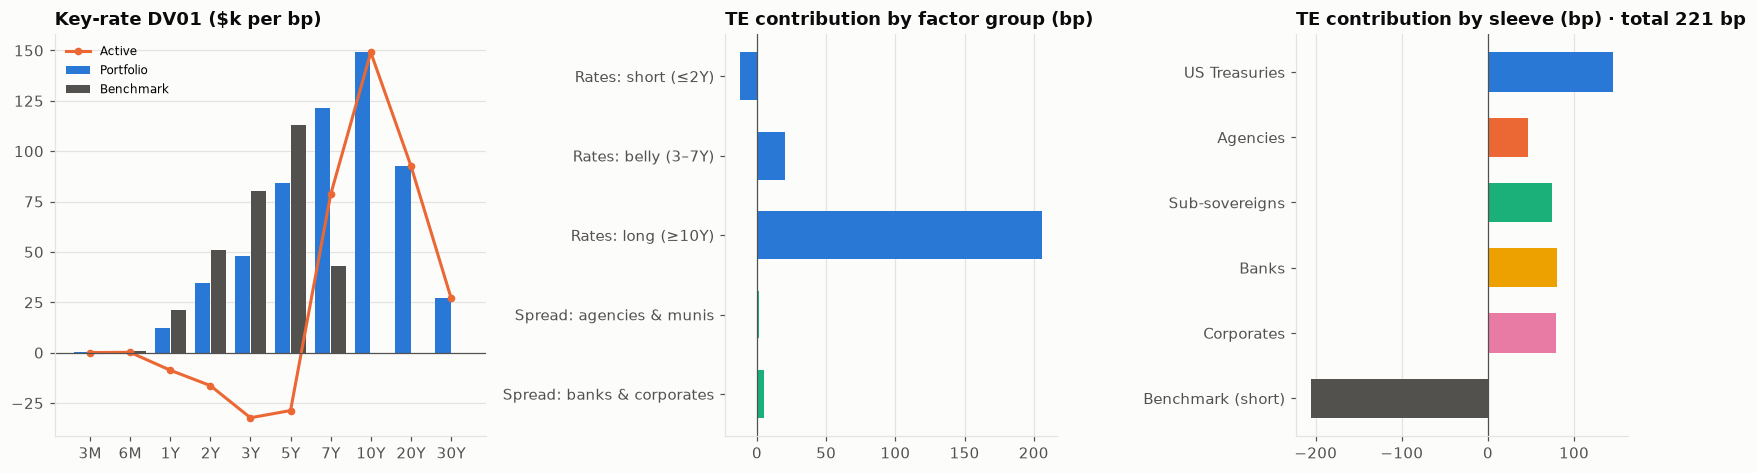

In [13]:
# --- Chart 1: the active curve position and the risk budget
fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.3, 1, 1]}
)
ax = axes[0]
port_kr = expo[expo["book"] == "Portfolio"][TENOR_COLS].sum().values / 1e3
bench_kr = expo[expo["book"] == "Benchmark"][TENOR_COLS].sum().values / 1e3
xs = np.arange(len(KEY_TENORS))
ax.bar(xs - 0.2, port_kr, width=0.38, color=PALETTE[0], label="Portfolio")
ax.bar(xs + 0.2, bench_kr, width=0.38, color=INK_2, label="Benchmark")
ax.plot(
    xs, port_kr - bench_kr, color=PALETTE[1], marker="o", ms=4, label="Active"
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xticks(xs, FACTORS[:10])
ax.set_title("Key-rate DV01 ($k per bp)")
ax.legend(fontsize=8)
ax.grid(axis="x", visible=False)

ax = axes[1]
g = by_group[::-1]
ax.barh(
    g.index,
    g.values,
    color=[PALETTE[2] if "Spread" in i else PALETTE[0] for i in g.index],
    height=0.6,
)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title(f"TE contribution by factor group (bp)")
ax.grid(axis="y", visible=False)

ax = axes[2]
s = by_sleeve[::-1]
ax.barh(
    s.index,
    s.values,
    color=[SLEEVE_COLORS.get(i, INK_2) for i in s.index],
    height=0.6,
)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title(f"TE contribution by sleeve (bp) · total {TE_EXANTE_BP:.0f} bp")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "01_active_risk_budget")
plt.show()

### 6.2 The curve bet in PCA terms

Projecting the active key-rate exposure on the first three principal components of curve moves shows the *nature* of the rate bet: mostly a level (duration) bet, or also slope and curvature positions? Each factor's risk is its exposure times its daily volatility.

In [14]:
pca = PCA(n_components=3).fit(factor_moves[FACTORS[:10]].values)
# bp per 1σ day
load = pca.components_.T * np.sqrt(pca.explained_variance_)
if load[:, 0].mean() < 0:
    load[:, 0] *= -1
if load[-1, 1] < load[0, 1]:
    load[:, 1] *= -1
if load[5, 2] < 0:
    load[:, 2] *= -1
pca_risk = pd.DataFrame(
    {
        "variance explained %": pca.explained_variance_ratio_ * 100,
        "active P&L per 1σ day ($k)": -(active_kr @ load) / 1e3,
        "annualised risk (bp of MV)": (
            np.abs(active_kr @ load) * np.sqrt(252) / PORTFOLIO_SIZE_USD * 1e4
        ),
    },
    index=["Level", "Slope", "Curvature"],
)
pca_risk.round(2)

,variance explained %,active P&L per 1σ day ($k),annualised risk (bp of MV)
Level,84.94,"-1,293.11",205.28
Slope,9.80,-579.39,91.98
Curvature,2.17,79.12,12.56


### 6.3 What would bring the portfolio inside its budget?

The portfolio here is *unhedged*, so its active duration is large. Two overlays an MDB treasury would consider, both with pay-fixed SOFR swaps (valued on the Treasury zero curve plus the swap-spread assumption):

1. **Duration-neutral:** one 10Y swap sized to set the active DV01 to zero.
2. **Minimum tracking error:** 2Y/5Y/10Y/30Y swaps chosen to minimise $\mathbf{x}^\top\boldsymbol\Sigma\mathbf{x}$, a closed-form least-squares problem: $\mathbf{n}^* = -(\mathbf{H}^\top\boldsymbol\Sigma\mathbf{H})^{-1}\mathbf{H}^\top\boldsymbol\Sigma\mathbf{x}$.

The credit-spread exposures stay, so the residual TE is the spread risk plus whatever curve risk the swaps cannot reach.

In [15]:
SWAP_SPREAD_BP = {2: -15, 3: -20, 5: -25, 7: -30, 10: -40, 20: -65, 30: -75}
spread_t, spread_v = (
    np.array(list(SWAP_SPREAD_BP)),
    np.array(list(SWAP_SPREAD_BP.values())) / 1e4,
)
HEDGE_TENORS = [2, 5, 10, 30]


def sofr_df(t, shift=None):
    return np.exp(
        -(
            zero_rate(t)
            + np.interp(t, spread_t, spread_v)
            + (0 if shift is None else shift(t))
        )
        * t
    )


def receiver_value(T, k, shift=None):
    pay = np.arange(1, T + 1, dtype=float)
    df = sofr_df(pay, shift)
    return k * df.sum() - (1 - df[-1])


par = {
    T: (1 - sofr_df(float(T))) / sofr_df(
        np.arange(1, T + 1, dtype=float)
    ).sum()
    for T in HEDGE_TENORS
}
# KR01 per $1 notional of a PAY-fixed swap (negative of the receiver's), padded
# with zero spread exposure
H = np.array([
    [
        receiver_value(T, par[T], bump) - receiver_value(T, par[T])
        for T in HEDGE_TENORS
    ]
    for bump in BUMPS
])
H = np.vstack([H, np.zeros((len(SPREAD_FACTOR), len(HEDGE_TENORS)))])
te_of = lambda v: np.sqrt(252 * v @ SIGMA @ v) / PORTFOLIO_SIZE_USD * 1e4

j10 = HEDGE_TENORS.index(10)
n_dur = np.zeros(len(HEDGE_TENORS))
n_dur[j10] = -x[:10].sum() / H[:10, j10].sum()
n_min = -np.linalg.solve(H.T @ SIGMA @ H, H.T @ SIGMA @ x)
overlays = pd.DataFrame({
    name: {
        **{
            f"{T}Y swap $mm (+pay / −receive fixed)": n[i] / 1e6
            for i, T in enumerate(HEDGE_TENORS)
        },
        "active duration (y)": (
            (x[:10] + (H @ n)[:10]).sum() / PORTFOLIO_SIZE_USD * 1e4
        ),
        "ex-ante TE (bp)": te_of(x + H @ n),
    }
    for name, n in {
        "No overlay": np.zeros(4),
        "Duration-neutral (10Y)": n_dur,
        "Minimum TE (2/5/10/30Y)": n_min,
    }.items()
}).T
overlays["budget use %"] = overlays["ex-ante TE (bp)"] / TE_BUDGET_BP * 100
overlays.round(2)

,2Y swap $mm (+pay / −receive fixed),5Y swap $mm (+pay / −receive fixed),10Y swap $mm (+pay / −receive fixed),30Y swap $mm (+pay / −receive fixed),active duration (y),ex-ante TE (bp),budget use %
No overlay,0.00,0.00,0.00,0.00,2.62,220.95,294.60
Duration-neutral (10Y),0.00,0.00,320.11,0.00,-0.00,95.96,127.95
Minimum TE (2/5/10/30Y),-184.37,-170.58,277.76,82.70,0.13,70.68,94.24


## 7. Ex-post: did the model get it right?

Three years of daily returns of an ETF replica: portfolio = 40% GOVT, 20% AGZ, 10% MUB and 30% IGIB (banks plus corporates); benchmark = 50% SHY + 50% IEI, rebalanced daily. ETFs are close but not exact proxies for our bonds, so ex-ante and ex-post TE should be of the same order, not identical.

In [16]:
# ETF weights of the replica
w_port = pd.Series(SLEEVE_TARGETS).groupby(SLEEVE_ETF).sum()
r_port = returns[w_port.index] @ w_port
r_bench = returns[list(BENCHMARK_FUNDS)] @ pd.Series(BENCHMARK_FUNDS)
active = (r_port - r_bench).rename("active")

TE_EXPOST_BP = active.std() * np.sqrt(252) * 1e4
ann_active_bp = active.mean() * 252 * 1e4
rolling_te = active.rolling(63).std() * np.sqrt(252) * 1e4
summary = pd.Series({
    "ex-ante TE (bp)": TE_EXANTE_BP,
    "ex-post TE, 3y (bp)": TE_EXPOST_BP,
    "ex-post TE, last 63 days (bp)": rolling_te.iloc[-1],
    "annualised active return (bp)": ann_active_bp,
    "information ratio": ann_active_bp / TE_EXPOST_BP,
    "portfolio return, 3y cumulative %": ((1 + r_port).prod() - 1) * 100,
    "benchmark return, 3y cumulative %": ((1 + r_bench).prod() - 1) * 100,
})
summary.round(2).to_frame("value")

,value
ex-ante TE (bp),220.95
"ex-post TE, 3y (bp)",206.27
"ex-post TE, last 63 days (bp)",183.55
annualised active return (bp),17.39
information ratio,0.08
"portfolio return, 3y cumulative %",12.60
"benchmark return, 3y cumulative %",12.20


### 7.1 Where did the active return come from?

**By sleeve (returns-based).** With sleeve weights $w_s$ and the benchmark return $R_b$, the active return is $\sum_s w_s (R_s - R_b)$ exactly, since the weights sum to one. Each term is a sleeve's contribution, aggregated by year in SQL.

**By factor (regression).** Daily active returns regressed on the same factor moves as the risk model, grouped into rates (short, belly, long) and spreads. The fitted part is the factor-driven return; the residual is selection and model error.

In [17]:
# Banks and corporates share the IGIB proxy ex-post, so they are reported as
# one line
EXPOST_LINES = {
    "US Treasuries": "GOVT",
    "Agencies": "AGZ",
    "Sub-sovereigns": "MUB",
    "Banks + Corporates": "IGIB",
}
contrib_daily = pd.DataFrame({
    line: w_port[etf] * (returns[etf] - r_bench)
    for line, etf in EXPOST_LINES.items()
})
con.register(
    "contrib",
    contrib_daily.reset_index().melt(
        id_vars="date", var_name="sleeve", value_name="r"
    ),
)
sleeve_year = (
    con.sql("""
    SELECT sleeve, YEAR(date) AS year, SUM(r) * 1e4 AS contribution_bp
    FROM contrib GROUP BY ALL ORDER BY sleeve, year
""")
    .df()
    .pivot(index="sleeve", columns="year", values="contribution_bp")
    .reindex(list(EXPOST_LINES))
)
sleeve_year["total (bp)"] = sleeve_year.sum(axis=1)
sleeve_year.round(1)

year,2023,2024,2025,2026,total (bp)
sleeve,,,,,
US Treasuries,37.20,-81.80,8.20,-41.90,-78.30
Agencies,-1.00,4.20,1.90,-0.10,4.90
Sub-sovereigns,11.00,-15.40,-20.20,-17.30,-42.00
Banks + Corporates,97.00,21.30,103.50,-53.10,168.70


In [18]:
reg_data = pd.concat(
    [active * 1e4, factor_moves], axis=1, join="inner"
).dropna()
group_cols = {
    "rates short": FACTORS[:4],
    "rates belly": FACTORS[4:7],
    "rates long": FACTORS[7:10],
    "spreads": FACTORS[10:],
}
# average move of each group (bp)
X = pd.DataFrame({g: reg_data[c].mean(axis=1) for g, c in group_cols.items()})
fit = sm.OLS(reg_data["active"], sm.add_constant(X)).fit()
# bp a year from each group
attrib = (fit.params[X.columns] * X).sum() / len(X) * 252
attrib["selection / residual"] = (fit.resid.mean() + fit.params["const"]) * 252
attr_table = pd.DataFrame({
    "sensitivity (bp of return per bp move)": fit.params[X.columns],
    "t-stat": fit.tvalues[X.columns],
}).round(3)
print(
    f"Factor regression R² = {fit.rsquared:.2f} · factors explain"
    f" {np.sqrt(fit.fittedvalues.var() * 252):.0f} bp of the"
    f" {TE_EXPOST_BP:.0f} bp ex-post TE"
)
print(
    "Annualised active return by source (bp): "
    + ", ".join(f"{k} {v:+.1f}" for k, v in attrib.items())
)
attr_table

Factor regression R² = 0.86 · factors explain 185 bp of the 206 bp ex-post TE
Annualised active return by source (bp): rates short -9.7, rates belly -1.3, rates long -21.4, spreads +31.3, selection / residual +91.2


,sensitivity (bp of return per bp move),t-stat
rates short,0.30,2.45
rates belly,0.81,7.06
rates long,-3.21,-37.12
spreads,-2.28,-14.95


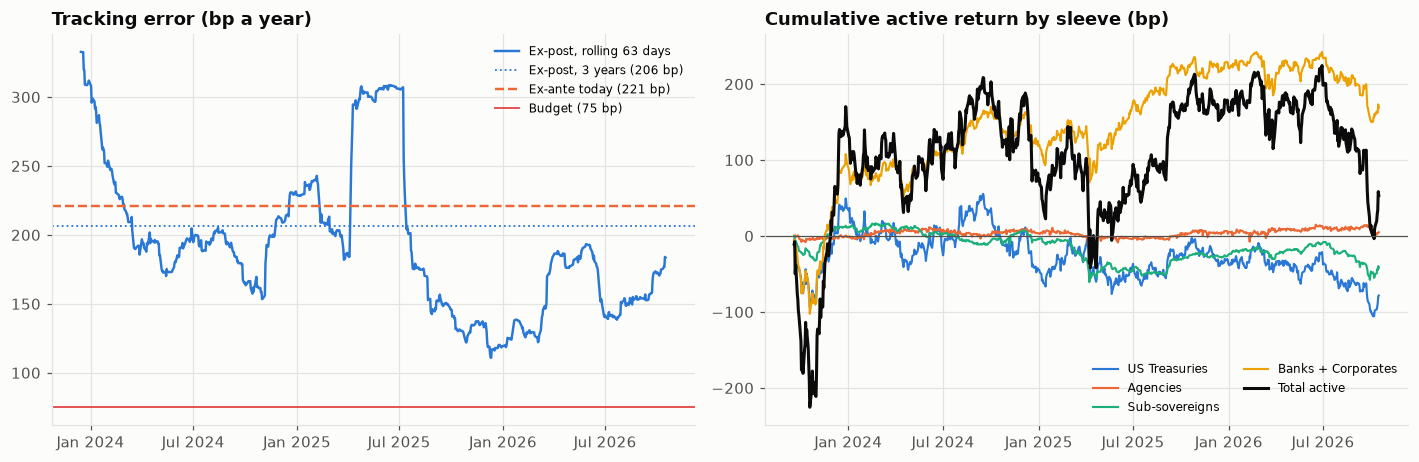

In [19]:
# --- Chart 2: ex-ante vs realised tracking error, and the active return path
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(
    rolling_te.index,
    rolling_te.values,
    color=PALETTE[0],
    lw=1.6,
    label="Ex-post, rolling 63 days",
)
ax.axhline(
    TE_EXPOST_BP,
    color=PALETTE[0],
    ls=":",
    lw=1.2,
    label=f"Ex-post, 3 years ({TE_EXPOST_BP:.0f} bp)",
)
ax.axhline(
    TE_EXANTE_BP,
    color=PALETTE[1],
    ls="--",
    lw=1.6,
    label=f"Ex-ante today ({TE_EXANTE_BP:.0f} bp)",
)
ax.axhline(
    TE_BUDGET_BP,
    color=STATUS["red"],
    lw=1.2,
    label=f"Budget ({TE_BUDGET_BP} bp)",
)
ax.set_title("Tracking error (bp a year)")
ax.legend(fontsize=8)

ax = axes[1]
cum = contrib_daily.cumsum() * 1e4
for s in EXPOST_LINES:
    ax.plot(
        cum.index,
        cum[s],
        color=SLEEVE_COLORS.get(s, PALETTE[3]),
        lw=1.4,
        label=s,
    )
ax.plot(cum.index, cum.sum(axis=1), color=INK, lw=2, label="Total active")
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_title("Cumulative active return by sleeve (bp)")
ax.legend(fontsize=8, ncol=2)
import matplotlib.dates as mdates

for a in axes:
    a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    a.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
save_fig(fig, "02_te_and_active_return")
plt.show()

## 8. Tracking-error dashboard

In [20]:
used = TE_EXANTE_BP / TE_BUDGET_BP * 100
light = (
    "🔴 above budget"
    if used > 100
    else ("🟡 close to budget" if used > 80 else "🟢 within budget")
)
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.16,
    horizontal_spacing=0.12,
    specs=[[{}, {}], [{}, {"type": "table"}]],
    subplot_titles=(
        "Active key-rate DV01 ($k per bp)",
        "TE contribution by sleeve (bp)",
        "Tracking error: rolling ex-post vs ex-ante (bp)",
        "Scorecard",
    ),
)
dash.add_trace(
    go.Bar(
        x=FACTORS[:10],
        y=port_kr - bench_kr,
        marker_color=[
            PALETTE[1] if v > 0 else PALETTE[0] for v in port_kr - bench_kr
        ],
        showlegend=False,
        name="Active KR01",
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        y=by_sleeve.index[::-1],
        x=by_sleeve.values[::-1],
        orientation="h",
        showlegend=False,
        marker_color=[
            SLEEVE_COLORS.get(i, INK_2) for i in by_sleeve.index[::-1]
        ],
        name="TE contribution",
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(
        x=rolling_te.index,
        y=rolling_te.values,
        name="Ex-post (63d)",
        line=dict(color=PALETTE[0], width=1.6),
    ),
    2,
    1,
)
for level, name, color, dashstyle in [
    (TE_EXANTE_BP, "Ex-ante today", PALETTE[1], "dash"),
    (TE_BUDGET_BP, "Budget", STATUS["red"], "solid"),
]:
    dash.add_trace(
        go.Scatter(
            x=[rolling_te.index[0], rolling_te.index[-1]],
            y=[level, level],
            name=name,
            mode="lines",
            line=dict(color=color, width=1.6, dash=dashstyle),
        ),
        2,
        1,
    )
rows = [
    ("Ex-ante TE", f"{TE_EXANTE_BP:.1f} bp"),
    ("Budget use", f"{used:.0f}% {light}"),
    ("Ex-post TE (3y)", f"{TE_EXPOST_BP:.1f} bp"),
    ("Active duration", f"{dur('Portfolio') - dur('Benchmark'):+.2f} y"),
    ("Active return (annualised)", f"{ann_active_bp:+.1f} bp"),
    ("Information ratio", f"{ann_active_bp / TE_EXPOST_BP:.2f}"),
    ("Largest risk source", f"{by_group.idxmax()} ({by_group.max():.1f} bp)"),
    (
        "TE with minimum-TE swap overlay",
        f"{overlays.loc['Minimum TE (2/5/10/30Y)', 'ex-ante TE (bp)']:.1f} bp",
    ),
]
dash.add_trace(
    go.Table(
        header=dict(
            values=["Metric", "Value"],
            fill_color="#f1f0ec",
            font=dict(color=INK, size=12),
            align="left",
        ),
        cells=dict(
            values=list(zip(*rows)),
            fill_color=SURFACE,
            font=dict(color=INK_2, size=12),
            align="left",
            height=28,
        ),
    ),
    2,
    2,
)
dash.update_layout(
    height=880,
    width=1350,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    legend=dict(orientation="h", y=-0.06),
    margin=dict(t=110, l=150),
    title=dict(
        x=0.01,
        text=(
            "<b>Tracking error vs 1–7Y Treasury benchmark ·"
            f" {EVAL_DATE:%d %b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>Ex-ante"
            f" {TE_EXANTE_BP:.0f} bp ({used:.0f}% of budget) · ex-post"
            f" {TE_EXPOST_BP:.0f} bp · information ratio"
            f" {ann_active_bp / TE_EXPOST_BP:.2f}</span>"
        ),
    ),
)
save_dashboard(dash, "dashboard")

decomp.to_csv(OUT_DIR / "te_decomposition_by_factor.csv")
by_sleeve.to_csv(OUT_DIR / "te_contribution_by_sleeve.csv")
sleeve_year.to_csv(OUT_DIR / "active_return_by_sleeve_year.csv")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

**How to read it**

- **The model is well calibrated.** Holdings-based ex-ante TE and the realised TE of the ETF replica come out within about 10% of each other, although they use different instruments and inputs.
- **This is a duration bet first.** The portfolio is about 2.6 years longer than a 1–7 year Treasury benchmark, and the 7–20 year key rates carry almost all of the risk. In PCA terms it is mostly a level position with a sizeable slope component. Against a 75 bp budget it is far outside its limit.

**Swaps fix it without selling bonds.** A single 10Y pay-fixed swap removes the duration gap and cuts TE by more than half, but leaves the curve-shape bet and stays above budget. The portfolio is *short* the 2–5 year part of the curve relative to the benchmark and long beyond 7 years.

The minimum-TE overlay (receive fixed at 2Y and 5Y, pay at 10Y and 30Y) neutralises both and brings TE inside the 75 bp budget, while keeping the credit pick-up that is the reason to hold agencies, munis and corporates.

- **Spreads diversify.** On their own the spread factors would be a meaningful source of TE. Credit spreads have tended to tighten when yields rose, so their *marginal* contribution is small. After the swap overlay they become the main residual risk.
- **Ex-post attribution.** The realised active return was small (information ratio close to zero). The SQL table shows the credit sleeves adding return while the long Treasuries and munis gave it back as rates rose. Banks and corporates share the IGIB proxy, so ex-post they are one line.

**Limitations**

- **No specific risk.** Issuer-level spread noise is not modelled, which understates TE for concentrated credit positions.
- **ETF proxies.** The ex-post replica uses fund returns, including the funds' own fees and their holdings beyond our 30 bonds per sleeve.
- **Static weights.** The ex-post replica is rebalanced daily to today's sleeve weights, and the ex-ante model uses today's holdings only.

## References

### Finance and regulation

- Litterman, R. (1996). Hot spots and hedges. *The Journal of Portfolio Management, 23*(5), 52–75. https://doi.org/10.3905/jpm.1996.052
- Roll, R. (1992). A mean/variance analysis of tracking error. *The Journal of Portfolio Management, 18*(4), 13–22. https://doi.org/10.3905/jpm.1992.701922
- Brinson, G. P., Hood, L. R., & Beebower, G. L. (1986). Determinants of portfolio performance. *Financial Analysts Journal, 42*(4), 39–44. https://doi.org/10.2469/faj.v42.n4.39
- Litterman, R., & Scheinkman, J. (1991). Common factors affecting bond returns. *The Journal of Fixed Income, 1*(1), 54–61. https://doi.org/10.3905/jfi.1991.692347
- Tasche, D. (2008). Capital allocation to business units and sub-portfolios: The Euler principle. In A. Resti (Ed.), *Pillar II in the new Basel Accord*. Risk Books. https://arxiv.org/abs/0708.2542

### Machine learning and deep learning

- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202. https://doi.org/10.1098/rsta.2015.0202
- Raasveldt, M., & Mühleisen, H. (2019). DuckDB: An embeddable analytical database. In *Proceedings of the 2019 International Conference on Management of Data*. https://doi.org/10.1145/3299869.3320212